# Sentiment Analysis Using Classical ML

**Course:** MIAI507 – Natural Language Processing
**Student:** Hadi Hijazi (redacted)

The IMDB dataset contains 50,000 movie reviews labelled *positive* or *negative*. The same classifier, Logistic Regression, is trained on four different representations of the text, to compare how much the choice of features matters:

1. word counts (CountVectorizer)
2. TF-IDF weights
3. pretrained word embeddings (GloVe)
4. word embeddings trained on this dataset (word2vec)

## Setup

`evaluate` is shared by Tasks 3 to 6: it trains a pipeline on the training set, prints its accuracy and classification report on the test set, and stores the accuracy for the comparison in Task 7.

In [1]:
import io
import os
import re
from contextlib import redirect_stderr

import gensim.downloader as api
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gensim.models import Word2Vec
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

RANDOM_STATE = 42
results = {}


def evaluate(name, model):
    """Train the model, print its test accuracy and classification report, and store the accuracy."""
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy
    print(f"{name}\nAccuracy: {accuracy:.4f}\n")
    print(classification_report(y_test, y_pred, target_names=["negative", "positive"], digits=4))
    return model

## Task 1 – Load the IMDB Movie Review Dataset

The dataset is the Kaggle [IMDB Dataset of 50K Movie Reviews](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews). `kagglehub` downloads the CSV file (and caches it for later runs), then pandas loads it.

In [2]:
dataset_dir = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")
df = pd.read_csv(os.path.join(dataset_dir, "IMDB Dataset.csv"))

print("Shape:", df.shape)
print(df["sentiment"].value_counts().to_string(), "\n")
df.head()

Shape: (50000, 2)
sentiment
positive    25000
negative    25000 



,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## Task 2 – Split the Dataset into Training and Testing

Two cleaning steps before splitting:

- **Duplicates:** the dataset contains some reviews more than once. They are removed so that the same review cannot appear in both the training and the test set, which would make the test accuracy look better than it is.
- **HTML line breaks:** the reviews contain `<br />` tags, which would otherwise become the word *br* in every model. They are replaced with spaces.

Features are the reviews and targets are the sentiments (1 = positive, 0 = negative). The split is 60% training and 40% testing, stratified so both sets keep the 50/50 class balance, with a fixed `random_state` so the results are reproducible.

In [3]:
n_before = len(df)
df = df.drop_duplicates(subset="review")
print(f"Removed {n_before - len(df)} duplicate reviews, {len(df):,} remain\n")

X = df["review"].str.replace(r"<br\s*/?>", " ", regex=True)
y = (df["sentiment"] == "positive").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE
)
print(f"Training examples: {len(X_train):,}")
print(f"Testing examples:  {len(X_test):,}")

Removed 418 duplicate reviews, 49,582 remain



Training examples: 29,749
Testing examples:  19,833


## Task 3 – Count Vectorizer + Logistic Regression

`CountVectorizer` turns each review into a vector of word counts over the vocabulary of the training set (bag of words). Logistic Regression then learns one weight per word. `max_iter` is raised because the default 100 iterations are not enough to converge on this many features.

In [4]:
count_model = evaluate(
    "Count + LR",
    make_pipeline(CountVectorizer(), LogisticRegression(max_iter=1000)),
)

Count + LR
Accuracy: 0.8857

              precision    recall  f1-score   support

    negative     0.8942    0.8741    0.8840      9879
    positive     0.8778    0.8973    0.8874      9954

    accuracy                         0.8857     19833
   macro avg     0.8860    0.8857    0.8857     19833
weighted avg     0.8859    0.8857    0.8857     19833



## Task 4 – TF-IDF Vectorizer + Logistic Regression

`TfidfTransformer` reweights the counts from `CountVectorizer`: words that appear in many reviews (*movie*, *film*, *the*) get a lower weight, and words specific to a few reviews get a higher one. It also normalizes each review vector to length 1, so long and short reviews are on the same scale.

In [5]:
tfidf_model = evaluate(
    "TF-IDF + LR",
    make_pipeline(CountVectorizer(), TfidfTransformer(), LogisticRegression(max_iter=1000)),
)

TF-IDF + LR
Accuracy: 0.8926

              precision    recall  f1-score   support

    negative     0.9059    0.8752    0.8903      9879
    positive     0.8802    0.9098    0.8947      9954

    accuracy                         0.8926     19833
   macro avg     0.8930    0.8925    0.8925     19833
weighted avg     0.8930    0.8926    0.8925     19833



## Task 5 – Pretrained Word Embeddings + Logistic Regression

**Pretrained model:** GloVe trained on Wikipedia and Gigaword (`glove-wiki-gigaword-100`, 400,000 words, 100 dimensions), loaded from gensim. The 100-dimensional version keeps the concatenation approach manageable: 200 words × 100 dimensions = 20,000 features per review, against 60,000 with 300 dimensions.

**Embedding vectorizer:** to be used inside a scikit-learn pipeline, a step must be a class with `fit` and `transform` methods. `EmbeddingVectorizer` inherits from `BaseEstimator` and `TransformerMixin`; `fit` does nothing (the embeddings are already trained) and `transform` turns each review into one vector. Reviews are lowercased and split into words, and words missing from the embedding vocabulary are skipped. Two approaches are compared:

- **Mean:** the average of the vectors of all the words in the review (100 features).
- **Concatenation:** the vectors of the first 200 words placed one after the other, padded with zeros when the review is shorter (20,000 features).

In [6]:
TOKEN_PATTERN = re.compile(r"[a-z]+")


def tokenize(text):
    return TOKEN_PATTERN.findall(text.lower())


class EmbeddingVectorizer(BaseEstimator, TransformerMixin):
    """Turn each review into a vector using word embeddings (gensim KeyedVectors)."""

    def __init__(self, embeddings, method="mean", max_words=200):
        self.embeddings = embeddings
        self.method = method
        self.max_words = max_words

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        dim = self.embeddings.vector_size
        n_features = dim if self.method == "mean" else dim * self.max_words
        vectors = np.zeros((len(X), n_features), dtype=np.float32)
        for i, text in enumerate(X):
            words = [w for w in tokenize(text) if w in self.embeddings]
            if not words:
                continue
            if self.method == "mean":
                vectors[i] = self.embeddings[words].mean(axis=0)
            else:
                words = words[: self.max_words]
                vectors[i, : len(words) * dim] = self.embeddings[words].ravel()
        return vectors


glove = api.load("glove-wiki-gigaword-100")
print(f"GloVe: {len(glove):,} words, {glove.vector_size} dimensions\n")

for method in ["mean", "concat"]:
    evaluate(
        f"GloVe {method} + LR",
        make_pipeline(EmbeddingVectorizer(glove, method), LogisticRegression(max_iter=1000)),
    )
    print("-" * 60)

best = max(["mean", "concat"], key=lambda m: results[f"GloVe {m} + LR"])
print(f"Best approach with GloVe: {best}")

GloVe: 400,000 words, 100 dimensions



GloVe mean + LR
Accuracy: 0.7985

              precision    recall  f1-score   support

    negative     0.7964    0.8000    0.7982      9879
    positive     0.8006    0.7970    0.7988      9954

    accuracy                         0.7985     19833
   macro avg     0.7985    0.7985    0.7985     19833
weighted avg     0.7985    0.7985    0.7985     19833

------------------------------------------------------------


GloVe concat + LR
Accuracy: 0.6836

              precision    recall  f1-score   support

    negative     0.6834    0.6795    0.6815      9879
    positive     0.6837    0.6876    0.6856      9954

    accuracy                         0.6836     19833
   macro avg     0.6836    0.6835    0.6835     19833
weighted avg     0.6836    0.6836    0.6836     19833

------------------------------------------------------------
Best approach with GloVe: mean


## Task 6 – Own Word2Vec Embeddings + Logistic Regression

A word2vec model (CBOW, gensim's default) is trained on the reviews of the **training set only**, so the test reviews stay unseen. Settings: 100 dimensions (same as GloVe, for a fair comparison), a context window of 5 words, words that appear fewer than 5 times are ignored, and 10 passes over the data.

The most similar words to *excellent* and *boring* are printed as a quick check that the model learned meaningful vectors. The same `EmbeddingVectorizer` and both approaches from Task 5 are then reused.

In [7]:
train_sentences = [tokenize(review) for review in X_train]

# gensim's compiled training code sometimes prints a harmless, empty
# "Exception ignored in: ...our_dot_float" message (no real exception occurs),
# so its stderr output is hidden during training only.
with redirect_stderr(io.StringIO()):
    w2v = Word2Vec(
        train_sentences,
        vector_size=100,
        window=5,
        min_count=5,
        epochs=10,
        workers=4,
        seed=RANDOM_STATE,
    )
own_embeddings = w2v.wv
print(f"Own word2vec: {len(own_embeddings):,} words, {own_embeddings.vector_size} dimensions")
for word in ["excellent", "boring"]:
    similar = ", ".join(w for w, _ in own_embeddings.most_similar(word, topn=6))
    print(f"  most similar to '{word}': {similar}")
print()

for method in ["mean", "concat"]:
    evaluate(
        f"Word2Vec {method} + LR",
        make_pipeline(EmbeddingVectorizer(own_embeddings, method), LogisticRegression(max_iter=1000)),
    )
    print("-" * 60)

best = max(["mean", "concat"], key=lambda m: results[f"Word2Vec {m} + LR"])
print(f"Best approach with own word2vec: {best}")

Own word2vec: 31,467 words, 100 dimensions
  most similar to 'excellent': outstanding, exceptional, terrific, superb, amazing, fantastic
  most similar to 'boring': dull, pointless, tedious, unoriginal, predictable, confusing



Word2Vec mean + LR
Accuracy: 0.8533

              precision    recall  f1-score   support

    negative     0.8578    0.8456    0.8517      9879
    positive     0.8489    0.8609    0.8548      9954

    accuracy                         0.8533     19833
   macro avg     0.8534    0.8532    0.8533     19833
weighted avg     0.8533    0.8533    0.8533     19833

------------------------------------------------------------


Word2Vec concat + LR
Accuracy: 0.7524

              precision    recall  f1-score   support

    negative     0.7524    0.7497    0.7510      9879
    positive     0.7525    0.7552    0.7538      9954

    accuracy                         0.7524     19833
   macro avg     0.7524    0.7524    0.7524     19833
weighted avg     0.7524    0.7524    0.7524     19833

------------------------------------------------------------
Best approach with own word2vec: mean


## Task 7 – Plot and Interpret the Results

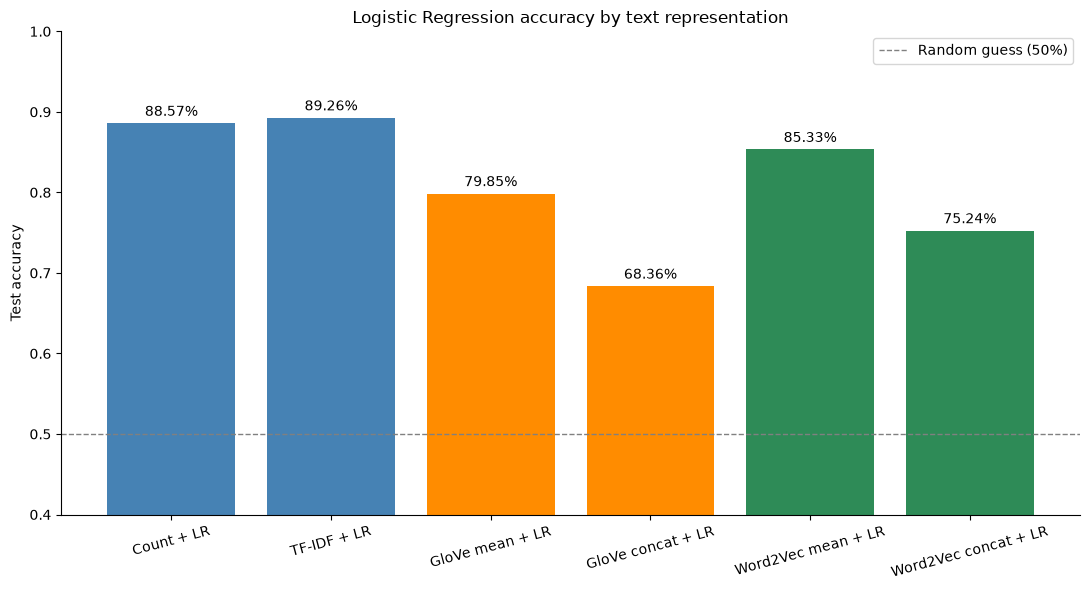

In [8]:
names = list(results)
accuracies = [results[n] for n in names]
colors = ["steelblue", "steelblue", "darkorange", "darkorange", "seagreen", "seagreen"]

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(names, accuracies, color=colors)
ax.bar_label(bars, labels=[f"{a:.2%}" for a in accuracies], padding=3)
ax.set_ylim(0.4, 1.0)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="Random guess (50%)")
ax.legend(loc="upper right")
ax.set_ylabel("Test accuracy")
ax.set_title("Logistic Regression accuracy by text representation")
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Interpretation

*Note: the y-axis starts at 40% to make the differences visible; the dashed line is the 50% accuracy of a random guess on this balanced dataset. The word2vec results can vary by about ±0.1% between runs, because training with several threads is not exactly reproducible.*

**1. Bag-of-words models are the best (TF-IDF 89.3%, Count 88.6%).**
CountVectorizer keeps every word of the training vocabulary (about 83,000) as its own feature, so Logistic Regression learns one weight per word. Movie-review sentiment is carried by specific words (*excellent*, *worst*, *waste*, *masterpiece*), and a linear model on individual words captures them directly. TF-IDF adds about 0.7 points: it lowers the weight of words that appear in almost every review (*movie*, *film*, *the*) and normalizes each review to length 1, so long reviews no longer get larger scores just because they have more words.

**2. Averaging word embeddings loses information (GloVe 79.9%, own word2vec 85.3%).**
Averaging squeezes a review of about 230 words into only 100 numbers. The few words that carry the opinion are mixed with all the neutral ones (plot, actors, characters), so their signal is diluted. In addition, embeddings place words that appear in similar contexts close together, and opposite opinions appear in the same contexts: in GloVe, *good* is the 2nd most similar word to *bad* (similarity 0.77). The averaged vectors of a positive and a negative review can therefore be quite close.

**3. Embeddings trained on the reviews beat the pretrained ones (+5.5 points).**
GloVe was trained on Wikipedia and news articles, where words are used differently than in movie reviews. The word2vec model trained on the IMDB training set learns the language of reviews: its closest words to *boring* are *dull*, *pointless*, *tedious*, *unoriginal* and *predictable*, all typical review vocabulary. Even with 31,000 words instead of 400,000, domain-specific vectors give clearly better features for this task.

**4. Concatenating the first 200 word vectors is the worst approach (GloVe 68.4%, own word2vec 75.2%).**
With concatenation, the same word lands on different features depending on its position: *excellent* as the 3rd word and as the 50th word are unrelated inputs for the model. Logistic Regression has to learn the effect of each word separately for each of the 200 positions, using 20,000 features and only about 30,000 training reviews, which is not enough data. Truncation also cuts the end of 41% of the test reviews, where reviewers often give their final verdict. A linear model cannot make use of word order in this form; a sequence model (RNN, LSTM or transformer) would be needed for that.

**Conclusion:** for a linear classifier, sparse TF-IDF features are the best choice here: they are the most accurate, simple, and fast to train. Word embeddings only pay off when they come from the same domain, and even then simple averaging loses too much information to beat the bag-of-words baseline.